In [1]:
import torch
import torch.nn as nn
from check import setup_torch

device = setup_torch()

import torch
print(torch.__version__)


✅ Using CUDA globally
GPU: NVIDIA GeForce RTX 4090
2.14.0+cu130


In [2]:
from helper.data_retrev import load_mels_with_labels_tuples
import resampy
import sys; sys.modules['librosa.core.audio.resampy'] = resampy

# Now call your original retrieval function safely
from helper.data_retrev import load_mels_with_labels_tuples

mels = load_mels_with_labels_tuples(saved_path="dataset_updated_labled_Local.pt",max_frames=1024 ,with_labels=True, labeling="bigger_set", folder="../../data_set/")


print(mels)
  # (n_mels, T_min)
  


🔄 Buffer Status: 1000/1000 (100.0% full)
💾 [Buffer Full] Saved shard 0 with 1000 samples to ../../json_data/dataset_updated_labled_Local.pt_part_0.pt
🔄 Buffer Status: 1000/1000 (100.0% full)
💾 [Buffer Full] Saved shard 1 with 1000 samples to ../../json_data/dataset_updated_labled_Local.pt_part_1.pt
🔄 Buffer Status: 1000/1000 (100.0% full)
💾 [Buffer Full] Saved shard 2 with 1000 samples to ../../json_data/dataset_updated_labled_Local.pt_part_2.pt
🔄 Buffer Status: 1000/1000 (100.0% full)
💾 [Buffer Full] Saved shard 3 with 1000 samples to ../../json_data/dataset_updated_labled_Local.pt_part_3.pt
🔄 Buffer Status: 1000/1000 (100.0% full)
💾 [Buffer Full] Saved shard 4 with 1000 samples to ../../json_data/dataset_updated_labled_Local.pt_part_4.pt
🔄 Buffer Status: 1000/1000 (100.0% full)
💾 [Buffer Full] Saved shard 5 with 1000 samples to ../../json_data/dataset_updated_labled_Local.pt_part_5.pt
🔄 Buffer Status: 1000/1000 (100.0% full)
💾 [Buffer Full] Saved shard 6 with 1000 samples to ../../js

In [ ]:
print(mels[1])

Found 978 files. Extracting durations...


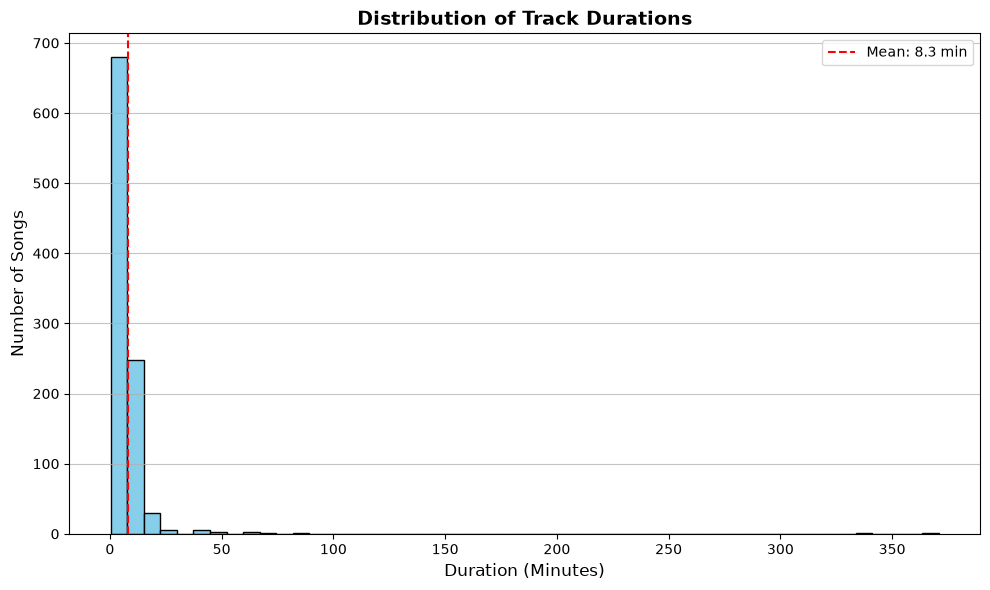

In [4]:
import glob
import os
import librosa
import matplotlib.pyplot as plt

# Set your data folder path
folder = "../../data_set/"
mp3_files = glob.glob(os.path.join(folder, "*.mp3"))

if len(mp3_files) == 0:
    print(f"No MP3 files found in {folder}")
else:
    durations = []
    print(f"Found {len(mp3_files)} files. Extracting durations...")
    
    for path in mp3_files:
        try:
            # Gets duration in seconds quickly without full audio decoding
            duration_sec = librosa.get_duration(path=path)
            durations.append(duration_sec / 60.0)  # Convert to minutes
        except Exception as e:
            print(f"⚠️ Error reading {os.path.basename(path)}: {e}")

    # Plotting the distribution histogram
    plt.figure(figsize=(10, 6))
    plt.hist(durations, bins=50, color='skyblue', edgecolor='black')
    plt.xlabel("Duration (Minutes)", fontsize=12)
    plt.ylabel("Number of Songs", fontsize=12)
    plt.title("Distribution of Track Durations", fontsize=14, fontweight='bold')
    plt.grid(axis='y', alpha=0.75)
    
    # Optional: add a vertical line for the mean/median to see where the 6-hour outlier sits
    mean_dur = sum(durations) / len(durations)
    plt.axvline(mean_dur, color='red', linestyle='--', linewidth=1.5, label=f"Mean: {mean_dur:.1f} min")
    plt.legend()
    
    plt.tight_layout()
    plt.show()

In [5]:
file_durations = []
for path in mp3_files:
    try:
        dur = librosa.get_duration(path=path) / 60.0
        file_durations.append((os.path.basename(path), dur))
    except Exception as e:
        print(f"Error with {os.path.basename(path)}: {e}")

# Sort by duration descending
file_durations.sort(key=lambda x: x[1], reverse=True)

print("Top 5 longest files in the folder:")
for name, dur in file_durations[:5]:
    print(f"- {name}: {dur:.2f} minutes ({dur/60:.2f} hours)")

Top 5 longest files in the folder:
- Ali Bin Rogha - Ma Loum Nafsi [ASQVhojPqOk].mp3: 370.79 minutes (6.18 hours)
- Mohamed Jumaa Khan - Kharaj Tha Fadl [RyioP9OGfyg].mp3: 334.01 minutes (5.57 hours)
- Abdel Halim Hafez - Mawoud [QzGVKJfZlWE].mp3: 82.02 minutes (1.37 hours)
- Mohamed Jumaa Khan - Eltoof Be Abdak [3hKjNTycxYw].mp3: 69.90 minutes (1.17 hours)
- Umm Kulthum - Hathehi Lailati [svfsPmqfdiM].mp3: 61.51 minutes (1.03 hours)


In [ ]:
from helper.data_retrev import load_mels_with_labels_tuples

mels2 = load_mels_with_labels_tuples(with_labels=False)


print(len(mels2))        # number of songs
  # (n_mels, T_min)